In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# بارگذاری فایل CSV
df = pd.read_csv(r"C:\Users\Lenovo\Desktop\dr.hoseyni\full_preprocessed_10H2O2_run2.csv",low_memory=False)

# تبدیل نوع داده (اگر لازم باشد)
df['TOTAL'] = pd.to_numeric(df['TOTAL'], errors='coerce')
df['Polar Solvation'] = pd.to_numeric(df['Polar Solvation'], errors='coerce')

# حذف ردیف‌های با داده‌های گمشده
df= df.dropna(subset=['Polar Solvation'])
df = df.dropna(subset=['TOTAL'])
# مرتب‌سازی داده‌ها
df_sorted = df.sort_values(by='TOTAL', ascending=True)

#print(df_sorted[['Residue','TOTAL']].head(10))

In [7]:
filtered_df=df_sorted
# ذخیره کردن داده‌های فیلتر شده به یک فایل جدید (اختیاری)
#filtered_df.to_csv('filtered_file.csv', index=False)

# نمایش داده‌های فیلتر شده (اختیاری)
#print(filtered_df)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_9940\1682659701.py:27: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('TOTAL_versus_Electrostatic_run2.png',dpi=300)


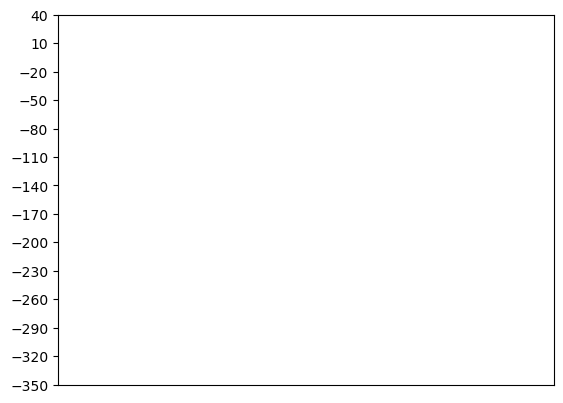

C:\Users\Lenovo\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


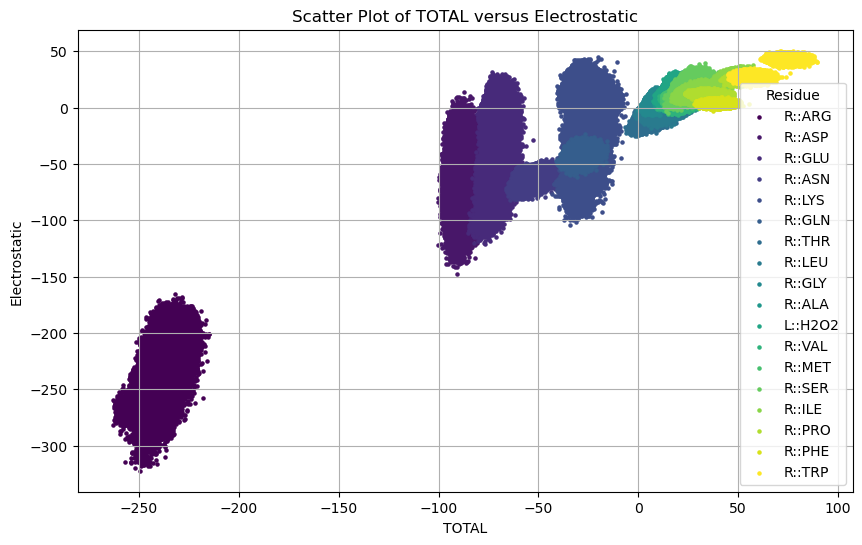

In [9]:
x = filtered_df ['TOTAL']  # جایگزین با نام ستون X
y = filtered_df ['Electrostatic']  # جایگزین با نام ستون Y
categories = filtered_df ['Residue']  # نام ستون دسته‌بندی

# تعیین رنگ‌ها بر اساس دسته‌بندی
unique_categories = categories.unique()
colors = plt.cm.viridis(np.linspace(0, 1, len(unique_categories)))

plt.xticks(np.arange(300,0, 20))  # خطوط در محور X با فاصله 0.5
plt.yticks(np.arange(-350, 60, 30))  # خطوط در محور Y با فاصله 0.1

# ایجاد دیکشنری برای نگاشت رنگ به دسته‌ها
category_color_map = {cat: colors[i] for i, cat in enumerate(unique_categories)}

plt.figure(figsize=(10, 6))

# رسم نقاط با رنگ‌های مختلف
for cat in unique_categories:
    subset = filtered_df [filtered_df ['Residue'] == cat]
    plt.scatter(subset['TOTAL'], subset['Electrostatic'], color=category_color_map[cat], label=cat,s=5)

plt.title('Scatter Plot of TOTAL versus Electrostatic')
plt.xlabel('TOTAL')
plt.ylabel('Electrostatic')
plt.legend(title='Residue')
plt.grid()
plt.savefig('TOTAL_versus_Electrostatic_run2.png',dpi=300)
plt.show()